# Phần 1.3 — Phân tích đơn biến và hai biến

Notebook này thực hiện **Bài toán 1** ở mục 1.3.2 với dữ liệu chim cánh cụt và giá nhà, cùng **Bài thực hành 1** ở mục 1.3.3 bằng SweetViz trên CSV thực tế hiện có.

## Phân tích yêu cầu

- **Đơn biến (univariate):** khảo sát từng cột riêng. Biến số: phân phối, trung vị, độ phân tán và ngoại lệ; biến phân loại: số lượng/tỷ lệ từng nhóm.
- **Hai biến (bivariate):** khảo sát mối liên hệ giữa hai cột. Hai biến số: scatterplot/correlation; số và phân loại: boxplot/violinplot; hai biến phân loại: bảng chéo hoặc biểu đồ cột.
- **Tương quan không chứng minh nhân quả.** Tương quan đo mức độ đồng biến tuyến tính và đã chuẩn hóa; hiệp phương sai cho biết chiều biến thiên chung nhưng phụ thuộc đơn vị đo.
- Biểu đồ tròn nên thể hiện tỷ trọng các nhóm bằng **số lượng** hoặc tỷ lệ. Không cộng chiều dài mỏ rồi dùng làm tỷ trọng loài; notebook dùng số lượng cá thể theo loài.

## Trước khi chạy

Ba CSV hiện có nằm cùng thư mục notebook: `penguins_lter.csv`, `HousingPrices-Amsterdam-August-2021.csv`, `diabetes.csv`. Đề PDF yêu cầu Marketing Campaign cho Bài thực hành 1, nhưng tệp này không có trong thư mục; phần SweetViz bên dưới được áp dụng cho `diabetes.csv` đang có và ghi rõ đây là dữ liệu thay thế.

In [3]:
# Bước 1: nạp thư viện dùng để đọc, kiểm tra và trực quan hóa dữ liệu.
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Bước 2: các CSV thực tế được đặt cạnh notebook; Path.cwd() lấy thư mục kernel đang chạy.
BASE_DIR = Path.cwd()
PENGUINS_CSV = BASE_DIR / "penguins_lter.csv"
HOUSING_CSV = BASE_DIR / "HousingPrices-Amsterdam-August-2021.csv"
DIABETES_CSV = BASE_DIR / "diabetes.csv"

# Bước 2a: nếu kernel mở từ thư mục khác, thử thư mục dự án hiện tại trước khi báo thiếu tệp.
if not all(path.is_file() for path in [PENGUINS_CSV, HOUSING_CSV, DIABETES_CSV]):
    project_data_dir = Path(r"d:\ML\sgu26k2_ML\Lab05")
    if all((project_data_dir / name).is_file() for name in [
        "penguins_lter.csv",
        "HousingPrices-Amsterdam-August-2021.csv",
        "diabetes.csv",
    ]):
        BASE_DIR = project_data_dir
        PENGUINS_CSV = BASE_DIR / "penguins_lter.csv"
        HOUSING_CSV = BASE_DIR / "HousingPrices-Amsterdam-August-2021.csv"
        DIABETES_CSV = BASE_DIR / "diabetes.csv"

# Bước 3: in thư mục và các CSV nhìn thấy để xác nhận đường dẫn ngay khi chạy.
print(f"Thư mục notebook đang chạy: {BASE_DIR}")
print("Các CSV trong thư mục:", sorted(path.name for path in BASE_DIR.glob("*.csv")))
missing_files = [path.name for path in [PENGUINS_CSV, HOUSING_CSV, DIABETES_CSV] if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Thiếu CSV: {missing_files}. Hãy đặt các tệp cạnh notebook hoặc sửa BASE_DIR.")

# Bước 4: hàm đọc CSV dùng chung; lỗi nêu đường dẫn tuyệt đối cần kiểm tra.
def read_csv_required(csv_path: Path) -> pd.DataFrame:
    if not csv_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu: {csv_path.resolve()}")
    return pd.read_csv(csv_path)


Thư mục notebook đang chạy: d:\ML\sgu26k2_ML\Lab05
Các CSV trong thư mục: ['HousingPrices-Amsterdam-August-2021.csv', 'diabetes.csv', 'penguins_lter.csv']


## Bài toán 1 — dữ liệu chim cánh cụt

Mục tiêu là làm quen với các biểu đồ/thống kê đơn biến và xem chiều dài mỏ thay đổi ra sao giữa các loài. CSV thực tế dùng tiêu đề `Species`, `Culmen Length (mm)` (viết hoa và có dấu cách), nên bước chuẩn hóa bên dưới đổi tên cột trước khi phân tích.

In [4]:
# Bước 1: đọc dữ liệu chim cánh cụt từ CSV mẫu.
penguins = read_csv_required(PENGUINS_CSV)

# Bước 2: chuẩn hóa tên cột để tránh lỗi do khoảng trắng thừa trong tiêu đề CSV.
penguins.columns = penguins.columns.str.strip()
penguins = penguins.rename(
    columns={
        "Species": "species",
        "Culmen Length (mm)": "culmen_length_mm",
        "Culmen Depth (mm)": "culmen_depth_mm",
        "Flipper Length (mm)": "flipper_length_mm",
        "Body Mass (g)": "body_mass_g",
    }
)

# Bước 3: xác nhận các cột cần cho bài toán có trong tệp.
required_penguin_columns = {"species", "culmen_length_mm"}
missing_columns = required_penguin_columns.difference(penguins.columns)
if missing_columns:
    raise ValueError(f"Thiếu cột bắt buộc trong dữ liệu chim cánh cụt: {sorted(missing_columns)}")

# Bước 4: chuyển chiều dài mỏ thành số; giá trị không hợp lệ sẽ thành NaN để được phát hiện.
penguins["culmen_length_mm"] = pd.to_numeric(penguins["culmen_length_mm"], errors="coerce")

# Bước 5: xem vài dòng, kiểu dữ liệu và số giá trị thiếu trước khi phân tích.
display(penguins.head())
display(penguins.dtypes.to_frame("data_type"))
display(penguins[["species", "culmen_length_mm"]].isna().sum().to_frame("missing_count"))

# Bước 6: giữ các hàng có đủ loài và chiều dài mỏ cho riêng các biểu đồ bên dưới.
penguins_clean = penguins.dropna(subset=["species", "culmen_length_mm"]).copy()
print(f"Số dòng ban đầu: {len(penguins):,}; sau khi bỏ thiếu ở hai cột cần dùng: {len(penguins_clean):,}")

# Bước 7: thống kê phân phối chiều dài mỏ (trung bình, trung vị, tứ phân vị, min/max).
display(penguins_clean["culmen_length_mm"].describe().to_frame("culmen_length_mm"))

# Bước 8: đếm số cá thể ở từng loài; đây là thống kê đơn biến cho biến phân loại.
species_counts = penguins_clean["species"].value_counts().sort_values(ascending=False)
display(species_counts.rename("count").to_frame())

,studyName,Sample Number,species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,11/11/07,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,11/11/07,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,11/16/07,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,11/16/07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,11/16/07,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN


,data_type
studyName,str
Sample Number,int64
species,str
Region,str
Island,str
Stage,str
Individual ID,str
Clutch Completion,str
Date Egg,str
culmen_length_mm,float64


,missing_count
species,0
culmen_length_mm,2


Số dòng ban đầu: 344; sau khi bỏ thiếu ở hai cột cần dùng: 342


,culmen_length_mm
count,342.000000
mean,43.921930
std,5.459584
min,32.100000
25%,39.225000
50%,44.450000
75%,48.500000
max,59.600000


,count
species,
Adelie Penguin (Pygoscelis adeliae),151
Gentoo penguin (Pygoscelis papua),123
Chinstrap penguin (Pygoscelis antarctica),68


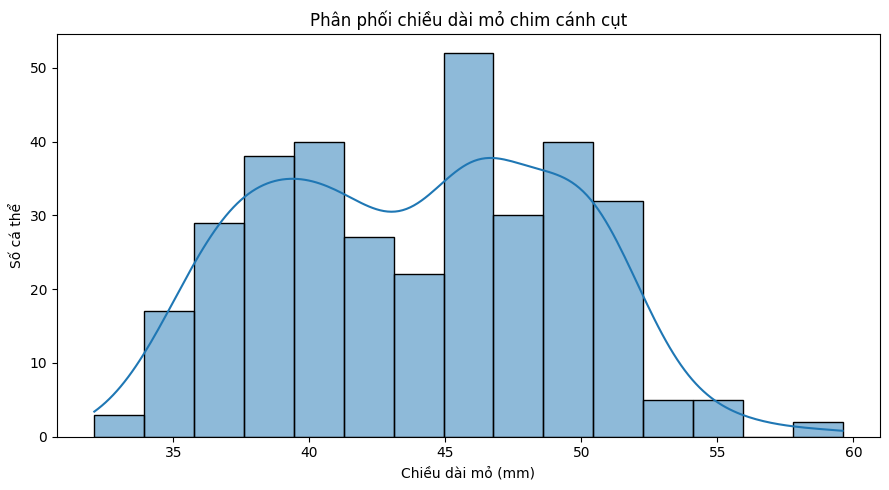

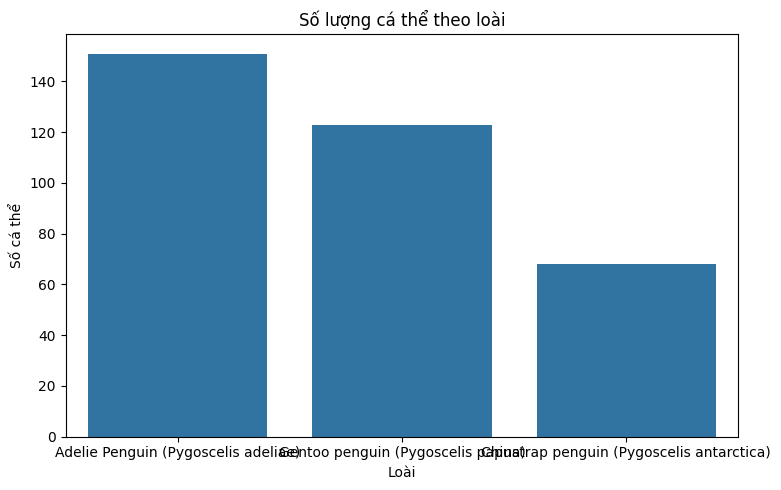

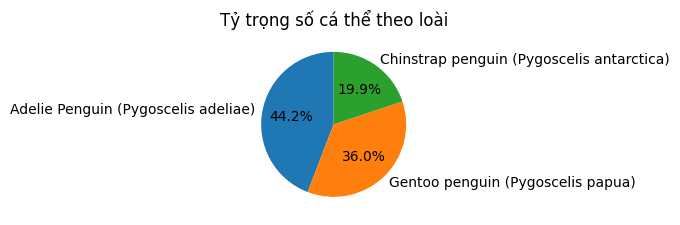

In [5]:
# Bước 1: vẽ histogram để quan sát phân phối của một biến số duy nhất.
plt.figure(figsize=(9, 5))
sns.histplot(data=penguins_clean, x="culmen_length_mm", bins=15, kde=True)
plt.xlabel("Chiều dài mỏ (mm)")
plt.ylabel("Số cá thể")
plt.title("Phân phối chiều dài mỏ chim cánh cụt")
plt.tight_layout()
plt.show()

# Bước 2: vẽ countplot để so sánh số lượng quan sát giữa các loài.
plt.figure(figsize=(8, 5))
sns.countplot(data=penguins_clean, x="species", order=species_counts.index)
plt.xlabel("Loài")
plt.ylabel("Số cá thể")
plt.title("Số lượng cá thể theo loài")
plt.tight_layout()
plt.show()

# Bước 3: vẽ pie chart từ số cá thể theo loài; tổng các lát bằng 100% dữ liệu hợp lệ.
plt.figure(figsize=(6, 6))
plt.pie(species_counts, labels=species_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Tỷ trọng số cá thể theo loài")
plt.tight_layout()
plt.show()

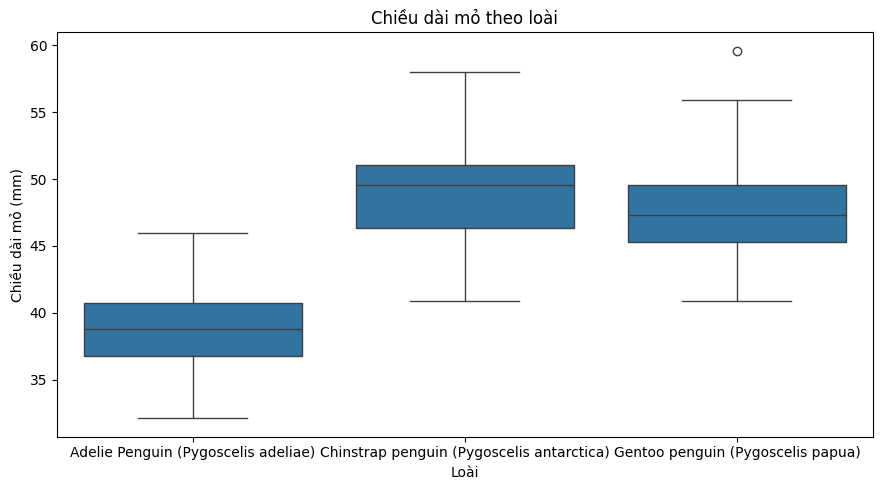

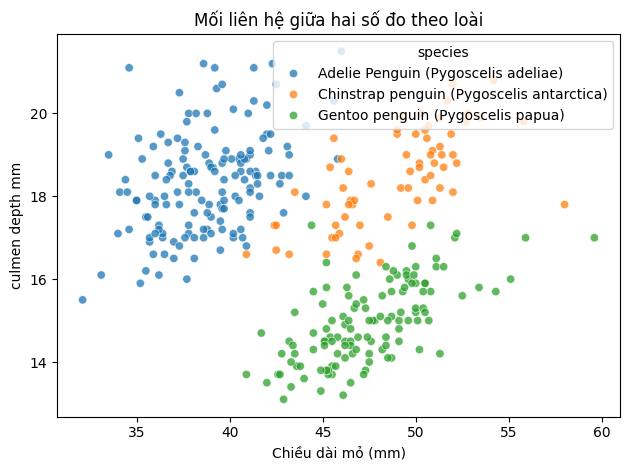

,count,median,q1,q3,iqr
species,,,,,
Adelie Penguin (Pygoscelis adeliae),151,38.80,36.75,40.750,4.000
Gentoo penguin (Pygoscelis papua),123,47.30,45.30,49.550,4.250
Chinstrap penguin (Pygoscelis antarctica),68,49.55,46.35,51.075,4.725


In [6]:
# Bước 1: boxplot ghép biến số chiều dài mỏ với biến phân loại loài.
# Đường giữa hộp là median; hộp là Q1–Q3; các điểm ngoài râu có thể là ngoại lệ.
plt.figure(figsize=(9, 5))
sns.boxplot(data=penguins_clean, x="species", y="culmen_length_mm")
plt.xlabel("Loài")
plt.ylabel("Chiều dài mỏ (mm)")
plt.title("Chiều dài mỏ theo loài")
plt.tight_layout()
plt.show()

# Bước 2: scatterplot thể hiện hai biến số; màu phân biệt loài để nhìn cấu trúc nhóm.
# Nếu CSV có culmen_depth_mm thì dùng nó; nếu không, dùng flipper_length_mm nếu có.
other_numeric = next(
    (column for column in ["culmen_depth_mm", "flipper_length_mm"] if column in penguins_clean.columns),
    None,
)
if other_numeric is not None:
    scatter_data = penguins_clean.dropna(subset=[other_numeric])
    sns.scatterplot(
        data=scatter_data,
        x="culmen_length_mm",
        y=other_numeric,
        hue="species",
        alpha=0.75,
    )
    plt.xlabel("Chiều dài mỏ (mm)")
    plt.ylabel(other_numeric.replace("_", " "))
    plt.title("Mối liên hệ giữa hai số đo theo loài")
    plt.tight_layout()
    plt.show()
else:
    print("CSV chỉ có hai cột mẫu; bỏ qua scatterplot vì không có số đo thứ hai.")

# Bước 3: in median và IQR theo loài để hỗ trợ nhận xét định lượng từ boxplot.
species_summary = penguins_clean.groupby("species")["culmen_length_mm"].agg(
    count="count",
    median="median",
    q1=lambda values: values.quantile(0.25),
    q3=lambda values: values.quantile(0.75),
)
species_summary["iqr"] = species_summary["q3"] - species_summary["q1"]
display(species_summary.sort_values("median"))

# Bước 4: diễn giải kết quả sau khi xem biểu đồ/bảng: so median, IQR, độ chồng lấp và ngoại lệ.
# Không kết luận quan hệ nhân quả chỉ từ các biểu đồ mô tả.

## Minh họa bổ sung trong Bài toán 1 — dữ liệu giá nhà

CSV Amsterdam có cột `Price` (giá EUR). Ô dưới đây mô tả phân phối giá bằng boxplot, sau đó tìm một số giá trị ngoài ngưỡng 1.5×IQR để kiểm tra thêm.

,Price (EUR)
count,9.200000e+02
mean,6.220654e+05
std,5.389942e+05
min,1.750000e+05
25%,3.500000e+05
50%,4.670000e+05
75%,7.000000e+05
max,5.950000e+06


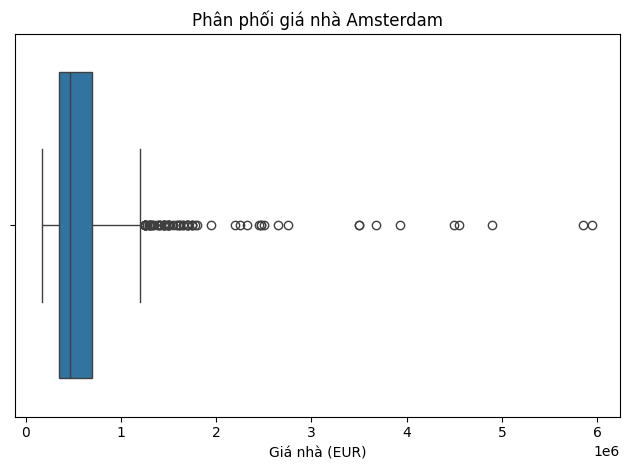

Số dòng ngoài ngưỡng 1.5×IQR: 71


,Unnamed: 0,Address,Zip,Price,Area,Room,Lon,Lat
20,21,"Keizersgracht 171 F, Amsterdam",1016 DP,1625000.0,199,6,4.885830,52.374742
28,29,"Colenbranderhof 30, Amsterdam",1065 BG,1650000.0,235,7,4.820848,52.358631
31,32,"Prinseneiland 545, Amsterdam",1013 EC,1950000.0,258,4,4.887444,52.385346
33,34,"Vondelstraat 51 hs, Amsterdam",1054 GJ,3925000.0,319,7,4.875471,52.361571
57,58,"Amstel 13, Amsterdam",1011 PT,1295000.0,145,5,4.899520,52.367261
88,89,"Geschutswerf 81, Amsterdam",1018 AW,1475000.0,220,5,4.920481,52.366984
103,104,"Westeinde 16, Amsterdam",1017 ZP,4550000.0,497,13,4.898620,52.358798
157,158,"Utrechtsedwarsstraat 4, Amsterdam",1017 WG,1700000.0,194,6,4.896542,52.360937
171,172,"Ouderkerkerdijk 34, Amsterdam",1096 CR,1300000.0,141,4,4.904363,52.333206
172,173,"Leonard Bernsteinstraat 96 A, Amsterdam",1082 MR,1750000.0,130,3,4.872151,52.336348


In [7]:
# Bước 1: đọc CSV giá nhà và xác nhận cột cần phân tích tồn tại.
housing = read_csv_required(HOUSING_CSV)
housing.columns = housing.columns.str.strip()
if "Price" not in housing.columns:
    raise ValueError(f"Không tìm thấy cột 'Price'. Các cột hiện có: {housing.columns.tolist()}")

# Bước 2: chuyển giá sang kiểu số; giá thiếu/không hợp lệ không tham gia thống kê này.
housing["Price"] = pd.to_numeric(housing["Price"], errors="coerce")
prices = housing["Price"].dropna()
if prices.empty:
    raise ValueError("Cột Price không có giá trị số hợp lệ để phân tích.")

# Bước 3: xem thống kê mô tả và vẽ boxplot giá theo EUR.
display(prices.describe().to_frame("Price (EUR)"))
sns.boxplot(x=prices)
plt.xlabel("Giá nhà (EUR)")
plt.title("Phân phối giá nhà Amsterdam")
plt.tight_layout()
plt.show()

# Bước 4: dùng ngưỡng 1.5×IQR để tìm điểm cần xem xét; không tự động xóa ngoại lệ.
q1, q3 = prices.quantile([0.25, 0.75])
iqr = q3 - q1
outlier_mask = (housing["Price"] < q1 - 1.5 * iqr) | (housing["Price"] > q3 + 1.5 * iqr)
print(f"Số dòng ngoài ngưỡng 1.5×IQR: {outlier_mask.sum():,}")
display(housing.loc[outlier_mask].head(10))

## Bài thực hành 1 — SweetViz với dữ liệu CSV hiện có

Đề PDF yêu cầu dùng Marketing Campaign, nhưng thư mục hiện có `diabetes.csv` (bộ dữ liệu tiểu đường Pima), không có Marketing Campaign. Để notebook chạy với dữ liệu đã cung cấp, phần này áp dụng SweetViz lên `diabetes.csv`; nếu cần đúng bộ Marketing Campaign thì thay đường dẫn `DIABETES_CSV` và tùy chỉnh phân tích. SweetViz tạo báo cáo HTML gồm kiểu dữ liệu, phân phối, giá trị thiếu, giá trị thường gặp và quan hệ giữa các cột.

Cài SweetViz trong đúng môi trường Python của notebook nếu chưa có: `%pip install sweetviz`.

In [8]:
# Bước 1: nạp đúng tệp diabetes.csv hiện có; lỗi sẽ nêu đường dẫn đầy đủ.
diabetes = read_csv_required(DIABETES_CSV)

# Bước 2: bỏ khoảng trắng thừa ở tên cột và xem kích thước, ví dụ dữ liệu, tên cột.
diabetes.columns = diabetes.columns.str.strip()
print(f"Số dòng: {diabetes.shape[0]:,}; số cột: {diabetes.shape[1]:,}")
print("Tên cột:", diabetes.columns.tolist())
display(diabetes.head())

# Bước 3: kiểm tra kiểu dữ liệu, giá trị thiếu, dòng trùng và số lượng giá trị phân biệt.
quality_report = pd.DataFrame(
    {
        "dtype": diabetes.dtypes.astype(str),
        "missing_count": diabetes.isna().sum(),
        "missing_percent": (diabetes.isna().mean() * 100).round(2),
        "distinct_count": diabetes.nunique(dropna=True),
    }
)
display(quality_report.sort_values("missing_percent", ascending=False))
print(f"Số dòng trùng hoàn toàn: {diabetes.duplicated().sum():,}")

# Bước 4: không tự ý xóa dòng trùng/điền thiếu trước khi xem báo cáo; ghi nhận để quyết định có căn cứ.
# Trong bộ Pima, số 0 ở một số chỉ số y khoa có thể mã hóa giá trị chưa đo.
zero_as_missing_candidates = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_as_missing_candidates = [column for column in zero_as_missing_candidates if column in diabetes.columns]
if zero_as_missing_candidates:
    display(
        diabetes[zero_as_missing_candidates]
        .eq(0)
        .sum()
        .rename("zero_count_to_review")
        .to_frame()
    )
if "Outcome" in diabetes.columns:
    print("Phân bố Outcome (0 = không tiểu đường, 1 = tiểu đường):")
    display(diabetes["Outcome"].value_counts(dropna=False).sort_index().to_frame("count"))

# Bước 5: import SweetViz tại đúng bước sử dụng để lỗi thiếu thư viện hiện rõ.
import sweetviz as sv

# Bước 6: phân tích dữ liệu và lưu báo cáo HTML cạnh notebook; không tự mở trình duyệt.
if "Outcome" not in diabetes.columns:
    raise ValueError(f"Thiếu cột Outcome trong diabetes.csv. Cột hiện có: {diabetes.columns.tolist()}")
report = sv.analyze(diabetes, target_feat="Outcome")
report_path = BASE_DIR / "reports" / "diabetes_sweetviz.html"
report_path.parent.mkdir(parents=True, exist_ok=True)
report.show_html(filepath=str(report_path), open_browser=False)
print(f"Đã tạo báo cáo SweetViz: {report_path.resolve()}")

Số dòng: 768; số cột: 9
Tên cột: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,dtype,missing_count,missing_percent,distinct_count
Pregnancies,int64,0,0.0,17
Glucose,int64,0,0.0,136
BloodPressure,int64,0,0.0,47
SkinThickness,int64,0,0.0,51
Insulin,int64,0,0.0,186
BMI,float64,0,0.0,248
DiabetesPedigreeFunction,float64,0,0.0,517
Age,int64,0,0.0,52
Outcome,int64,0,0.0,2


Số dòng trùng hoàn toàn: 0


,zero_count_to_review
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Phân bố Outcome (0 = không tiểu đường, 1 = tiểu đường):


,count
Outcome,
0,500
1,268


C:\Users\DELL\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)


Report d:\ML\sgu26k2_ML\Lab05\reports\diabetes_sweetviz.html was generated.
Đã tạo báo cáo SweetViz: D:\ML\sgu26k2_ML\Lab05\reports\diabetes_sweetviz.html


## Cách viết nhận xét sau khi mở báo cáo

1. Ghi số dòng/cột, kiểu dữ liệu, cột thiếu và cột có giá trị phân biệt bất thường.
2. Với `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, kiểm tra số 0 vì có thể mã hóa chỉ số chưa đo; không tự đổi thành NaN nếu chưa xác nhận quy ước dữ liệu.
3. Mô tả phân phối, độ lệch và ngoại lệ; phân biệt dữ liệu đáng ngờ với giá trị cực trị nhưng hợp lệ.
4. Xem các biến thay đổi thế nào theo `Outcome` (0/1). Đây là quan hệ mô tả, không chứng minh nguyên nhân.
5. Đề xuất bước tiền xử lý tiếp theo (mã 0/thiếu, kiểu dữ liệu, trùng, ngoại lệ); không tự động xóa dữ liệu chỉ vì SweetViz đánh dấu.
6. Kết quả này áp dụng trên `diabetes.csv`, không phải báo cáo Marketing Campaign trong PDF.